In [1]:
from os.path import join, dirname
import os
import sys
import gc
import logging
import argparse
from copy import deepcopy
import numpy as np
import torchshow as ts
import torchvision
from einops import rearrange, repeat
from matplotlib import pyplot as plt

import torch
from torch import autocast
from torch.cuda.amp import GradScaler
import torch.nn.functional as F
import torch.distributed as dist
import torch.multiprocessing as mp
from torch.autograd import grad, Variable

sys.path.append(join(dirname(dirname(os.getcwd()))))
sys.path.append(os.getcwd())

from memoryPerceiver.memory_perceiver.main.configuration import cf
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_memories, reset_memories
from memoryPerceiver.memory_perceiver.core.distributed import setup_distributed, average_gradients, scatter_dummy_src, gather_dummy_src
from memoryPerceiver.memory_perceiver.core.miscellaneous import custom_random, print_cuda_tensors
import memoryPerceiver.memory_perceiver.isaac.trainer as tr
from memoryPerceiver.memory_perceiver.isaac.plot import Plotter
from memoryPerceiver.memory_perceiver.isaac.agent import ActorCritic, ActorCriticSimple, ActorCriticPerceiver, create_agent

from memoryPerceiver.memory_perceiver.core.model_net import PerceiverIO
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_multimodal_perceiver, output_projection, input_embedding
from memoryPerceiver.memory_perceiver.core.rnn import SimpleRNN
from memoryPerceiver.memory_perceiver.core.uoro import UOROModel
from memoryPerceiver.memory_perceiver.core.rnn import SimpleRNN
from memoryPerceiver.memory_perceiver.core.my_uoro import UORO

%load_ext autoreload
%autoreload 2
device = 'cuda:0'

In [2]:
import numpy as np


def one_hot_encode(value, n_class):
    vec = np.zeros([n_class])
    vec[value] = 1
    return vec


def one_hot_decode(encoded_seq):
    return [np.argmax(vector) for vector in encoded_seq]


def get_an_bn_array(num_data, k, l):
    """
    modified from https://github.com/petered/uoro-demo
    """
    x = np.zeros([num_data], dtype=int)

    i = 0
    while i < num_data:
        n = np.random.randint(low=k, high=l+1)
        x[i:i+n] = 1
        x[i+n+1: i+2*n+1] = 2
        i += 2*n + 2
    return x


def generate_anbn_data(num_data, k=1, l=4, num_class=3):
    X_arr = get_an_bn_array(num_data+1, k, l)
    X = np.zeros([1, num_data, num_class])
    Y = np.zeros([1, num_data, num_class])
    for i in range(num_data):
        X[0, i] = one_hot_encode(X_arr[i], num_class)
        Y[0, i] = one_hot_encode(X_arr[i+1], num_class)
    return X, Y


X, Y = generate_anbn_data(10000, k=1, l=4, num_class=3)
X = torch.from_numpy(X).float().to(device)
Y = torch.from_numpy(np.argmax(Y, axis=2)).long().to(device)

In [5]:
loss_all=[]
l = []
loss_acc=0
input_size=3
hidden_size=10
output_size=3
old_s = torch.zeros(size=[1, 1, hidden_size], requires_grad=True, device=device)
criterion=torch.nn.CrossEntropyLoss()
model=SimpleRNN(3,hidden_size,3).to(device)
uoro_grad = UORO(model)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [6]:
# UORO
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        y_t = Y[:, iter_id:(iter_id+1)].reshape([1]).to(device)

        y, new_s = model(x_t, old_s)
        loss=criterion(y[0], y_t)
        uoro_grad.step(model, x_t, new_s, old_s, loss)
        old_s = new_s.detach().clone().requires_grad_(True)
        optimizer.step()
        optimizer.zero_grad()
        loss_all.append(loss.item())
        loss_acc += loss.item()
        if iter_id%1000 == 0:
            print(loss_acc)
            loss_acc=0

0.8186137080192566


1110.0125734210014
1082.51436907053
970.2251855432987
732.2609183490276
604.5340087395161
489.00804404262453
470.10345702059567
412.05286311055534
355.8553316407779
326.8326158416312
296.3896863776099
287.8711085838404
277.39712307433365
264.8540746735853
248.60749511900485
274.88544093007374
276.1085630179846


KeyboardInterrupt: 

In [ ]:
# BPTT
loss=torch.tensor(0.0, device=device)
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        y_t = Y[:, iter_id:(iter_id+1)].reshape([1]).to(device)

        y, new_s = model(x_t, old_s)
        loss+=criterion(y.squeeze(0), y_t)
        # uoro_grad.step(model, x_t, new_s, old_s, loss)
        if iter_id % 5 == 0:
            optimizer.zero_grad()
            loss.backward()
            old_s = new_s.detach().clone().requires_grad_(True)
            optimizer.step()
            loss_all.append(loss.item()/5)
            loss_acc += loss.item()
            loss=torch.tensor(0.0, device=device)
        else:
            old_s = new_s.clone() #.detach().clone()  #.detach().clone().requires_grad_(True)
        
        if iter_id%100 == 0:
            print(loss_acc)
            loss_acc=0

In [19]:
from memoryPerceiver.memory_perceiver.main.configuration import cf
loss_all = []
loss_acc=0
criterion=torch.nn.CrossEntropyLoss()
cf.body_outputs['critic']=3 # agent.py -> values = rearrange(output['critic'], 'b () d -> b d')
cf.shared=True 
cf.dim_observations=3
cf.num_envs=1
cf.depth=1
cf.query_dim=4
cf.nb_latents=2
cf.nb_latents_mem=2
cf.latent_dim_head=2
model=create_agent(cf, device)
old_s = create_memories(model.actor, cf.num_envs, device=device)
mem_dim = old_s.shape
old_s = rearrange(old_s, 'b d l h -> (b d l h)')
uoro_grad = UORO(model)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
model.train()
dummy0=torch.zeros(cf.num_envs, 1, cf.dim_actions, device=device)
states = {}

In [10]:
print(uoro_grad.theta_tilda.shape)

torch.Size([1325])


In [20]:
# UORO
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        states['observations'] = repeat(x_t, '() t d -> b t d', b=cf.num_envs)
        y_t = Y[:   , iter_id:(iter_id+1)].reshape([1]).to(device)
        y_t = repeat(y_t, '1 -> b', b=cf.num_envs)
        _, y, _, new_s = model(states, old_s, old_actions=dummy0, flattened_mem=mem_dim)
        # y = torch.nn.functional.softmax(y)
        loss=criterion(y, y_t)
        uoro_grad.step(model, states, new_s, old_s, loss, old_actions=dummy0, flattened_mem=mem_dim)
        # loss.backward()
        old_s = new_s.detach().clone().requires_grad_(True)
        optimizer.step()
        optimizer.zero_grad()
        loss_all.append(loss.item())
        loss_acc += loss.item()
        if iter_id%1000 == 0:
            print(loss_acc)
            loss_acc=0

1.045325756072998
1100.3778955936432
1095.8820570707321
1093.4737958312035


KeyboardInterrupt: 

In [ ]:
# BPTT
loss=torch.tensor(0.0, device=device)
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        states['observations'] = repeat(x_t, '() t d -> b t d', b=cf.num_envs)
        y_t = Y[:, iter_id:(iter_id+1)].reshape([1]).to(device)
        y_t = repeat(y_t, '1 -> b', b=cf.num_envs)

        _, y, _, new_s = model(states, old_s, old_actions=dummy0, flattened_mem=mem_dim)
        loss+=criterion(y, y_t)
        if iter_id % 5 == 0:
            optimizer.zero_grad()
            loss.backward()
            old_s = new_s.detach().clone().requires_grad_(True)
            optimizer.step()
            loss_all.append(loss.item()/5)
            loss_acc += loss.item()
            loss=torch.tensor(0.0, device=device)
        else:
            old_s = new_s.clone() #.detach().clone()  #.detach().clone().requires_grad_(True)
        
        if iter_id%100 == 0:
            print(loss_acc)
            loss_acc=0

In [106]:
for param_group in optimizer.param_groups:
    param_group['lr'] = 1e-6

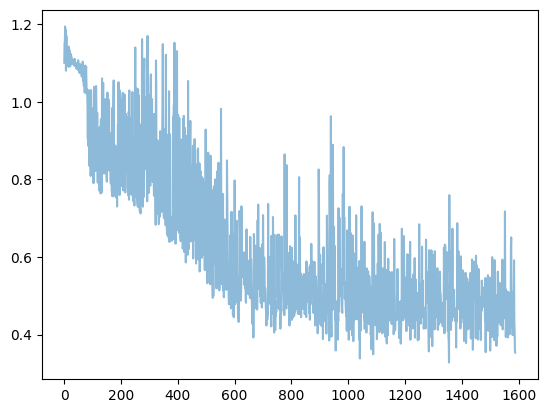

In [18]:
# < 0.68 and close to 0.25 RNN
# plt.plot(loss_all)
h=10
plt.plot([sum(loss_all[i: i+h])/h for i in range(0,len(loss_all),h)], alpha=0.5)
# plt.scatter(x=list(range(0,len(loss_all),h)) , y=[sum(loss_all[i: i+h])/h for i in range(0,len(loss_all),h)], alpha=0.1)
plt.show()

In [ ]:
torch.tensor(loss_all)[:5000].mean()